# The real data in a three-dimensional representation

**What this is.** The same question as in the toy notebooks — where does the domain signal go? —
asked of the *actual* Baikal-GVD data, with a network small enough to train on a CPU in a couple of
minutes and a representation $z \in \mathbb{R}^3$ small enough to plot.

**What is different from the production run.** Everything here is a miniature of it:

| | this notebook | the production run |
|---|---|---|
| events | 20 000 per domain (a random sample) | 5.2 M per domain |
| hits per event | truncated at 64 | up to 500 |
| encoder | 1 transformer layer, $d=32$, $z\in\mathbb{R}^3$ | 4 layers, $d=128$, $z\in\mathbb{R}^{128}$ |
| classifier / discriminator | MLPs $3\!\to\!32\!\to\!1$ | same heads, on $z\in\mathbb{R}^{128}$ |
| training | 1500 steps | 100 epochs |
| **batch construction** | **exactly as in the production script** (see §3) | — |

**The four clouds**, named by colour throughout:

| colour | what | domain | class |
|---|---|---|---|
| blue | `muatm` (atmospheric muons) | source | background |
| green | `nuatm` + `nue2` (neutrinos) | source | signal |
| red | `exp` (real data, as recorded) | target | unknown |
| orange | `exp` with the $z$-coordinate flipped | target | unknown |

The orange cloud is not extra data: it is the *same* target events with $z \to -z$ (the detector's
vertical coordinate). This mirroring is part of the production recipe — see §3 — and it is the
reason the discriminator cannot use "up-going or down-going" to tell the domains apart. Physically
it turns a down-going event into an up-going one, and since neutrinos arrive from below, the
flipped events are *fake up-going background*: exactly the population a neutrino search has to
reject.

## 1. The data

Both datasets are the memory-mapped NPY arrays produced by `data_manager/nu_classifier_ds_builder`
(hits that passed the signal/noise model at threshold 0.8). Runs must be started from the repository
root.

Features per hit: $(Q, t, x, y, z)$ — charge, time, and cluster-centred coordinates. They are
normalized with the constants used in production (`data_manager/stats_dict/default_mc.yaml`).

In [1]:
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

def find_repo_root(marker="data_manager/datasets/nu_classifier_dataset_h5s0_thr0.8"):
    # the notebook may be run from its own directory; walk up until the data are found
    here = Path.cwd()
    for cand in (here, *here.parents):
        if (cand / marker).exists():
            return cand
    raise SystemExit(f"repository root not found above {here}")


ROOT = find_repo_root()
SRC_DIR = ROOT / "data_manager/datasets/nu_classifier_dataset_h5s0_thr0.8"
TGT_DIR = ROOT / "data_manager/datasets/nu_classifier_dataset_exp_full_thr0.8"
print("repository root:", ROOT)

# normalization constants of the production pipeline
MEANS = np.array([2.0, 0.0, 0.0, 0.0, 0.0], dtype=np.float32)      # Q, t, x, y, z
STDS = np.array([60.0, 1370.0, 40.0, 40.0, 150.0], dtype=np.float32)
FEATURES = ["Q", "t", "x", "y", "z"]
Z_INDEX = 4                     # column that the z-flip mirrors

N_SAMPLE = 20000                # events drawn per domain
N_TRAIN = 16000                 # of which used for training; the rest are held out
MAX_HITS = 64
COLORS = {"b": "#1f77b4", "g": "#2ca02c", "r": "#d62728", "o": "#ff7f0e"}
NAMES = {"b": "muatm (source, background)", "g": "nuatm+nue2 (source, signal)",
         "r": "exp (target)", "o": "exp, z-flipped (target)"}


def load_events(features_path, offsets_path, n_max, seed):
    # random sample of events; each event is a (n_hits, 5) array, truncated to MAX_HITS
    feats = np.load(features_path, mmap_mode="r")
    offsets = np.load(offsets_path)
    n_events = len(offsets) - 1
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(n_events, size=min(n_max, n_events), replace=False))
    events = []
    for i in idx:
        a, b = int(offsets[i]), int(offsets[i + 1])
        events.append(np.asarray(feats[a:min(b, a + MAX_HITS)], dtype=np.float32))
    return events, idx


t0 = time.time()
src_events, src_idx = load_events(SRC_DIR / "features.npy", SRC_DIR / "offsets.npy",
                                  N_SAMPLE, seed=0)
tgt_events, tgt_idx = load_events(TGT_DIR / "exp_features.npy", TGT_DIR / "exp_offsets.npy",
                                  N_SAMPLE, seed=0)
src_type = np.load(SRC_DIR / "particle_types.npy")[src_idx]     # 0 = muatm, 1 = nuatm, 2 = nue2
print(f"loaded {len(src_events)} source and {len(tgt_events)} target events in {time.time()-t0:.1f} s")

# normalize with the production constants
src_events = [(e - MEANS) / STDS for e in src_events]
tgt_events = [(e - MEANS) / STDS for e in tgt_events]

n_mu = int((src_type == 0).sum())
n_nu = int((src_type > 0).sum())
print(f"source: {n_mu} muatm, {n_nu} neutrinos (nuatm {int((src_type==1).sum())}, "
      f"nue2 {int((src_type==2).sum())})")

repository root: /home/albert/Baikal2025
loaded 20000 source and 20000 target events in 0.5 s
source: 10013 muatm, 9987 neutrinos (nuatm 5067, nue2 4920)


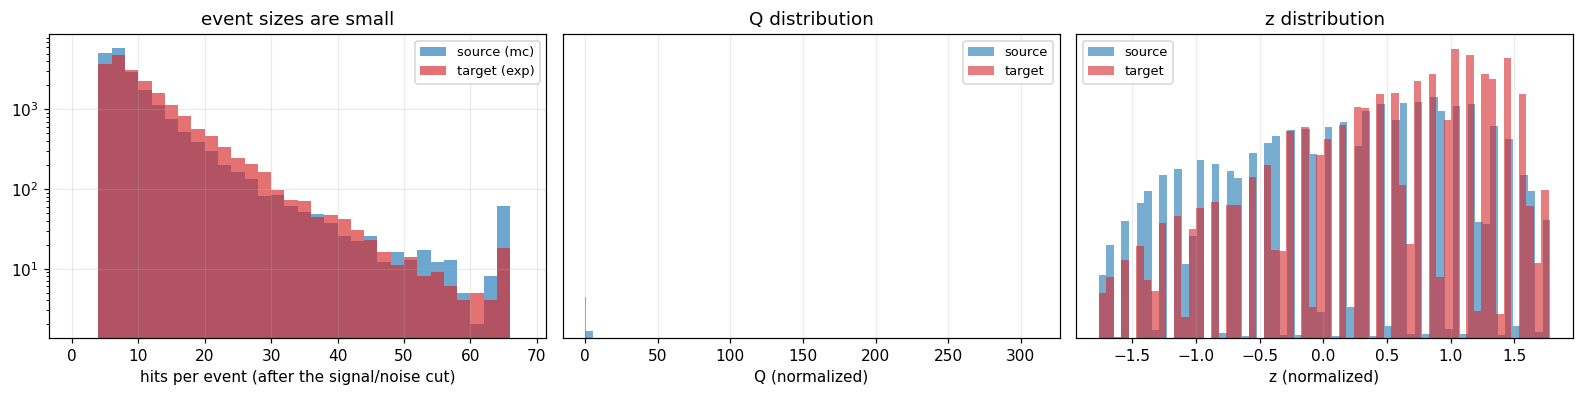

median hits: source 7, target 8; 90th percentile 17 / 19


In [2]:
hits_src = np.array([len(e) for e in src_events])
hits_tgt = np.array([len(e) for e in tgt_events])

fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.7))
axes[0].hist(hits_src, bins=np.arange(0, 70, 2), alpha=0.65, color="#1f77b4", label="source (mc)")
axes[0].hist(hits_tgt, bins=np.arange(0, 70, 2), alpha=0.65, color="#d62728", label="target (exp)")
axes[0].set_xlabel("hits per event (after the signal/noise cut)"); axes[0].set_yscale("log")
axes[0].legend(fontsize=8.5); axes[0].set_title("event sizes are small")

all_src = np.concatenate([e for e in src_events[:4000]])
all_tgt = np.concatenate([e for e in tgt_events[:4000]])
for ax, j, name in ((axes[1], 0, "Q"), (axes[2], Z_INDEX, "z")):
    ax.hist(all_src[:, j], bins=60, alpha=0.6, color="#1f77b4", label="source", density=True)
    ax.hist(all_tgt[:, j], bins=60, alpha=0.6, color="#d62728", label="target", density=True)
    ax.set_xlabel(f"{name} (normalized)"); ax.set_yticks([]); ax.legend(fontsize=8.5)
    ax.set_title(f"{name} distribution")
plt.tight_layout(); plt.show()

print(f"median hits: source {int(np.median(hits_src))}, target {int(np.median(hits_tgt))}; "
      f"90th percentile {int(np.quantile(hits_src, 0.9))} / {int(np.quantile(hits_tgt, 0.9))}")

## 2. The model

A miniature of the production encoder: project the five hit features to $d = 32$, prepend a learned
class token, run one transformer layer, and read the class token out through a linear layer to
$z \in \mathbb{R}^3$:

$$
z \;=\; W_{\text{out}}\,\mathrm{CLS}\Big(\mathrm{Transformer}\big[\,\mathrm{CLS},\; W_{\text{in}} x_1, \dots, W_{\text{in}} x_n\,\big]\Big).
$$

Two heads read $z$: the classifier $C_\psi$ (MLP $3\!\to\!32\!\to\!1$, trained on the source labels)
and the discriminator $D_\phi$ (same shape, trained on the domain labels). The adversarial coupling
is the gradient-reversal layer, as in the production trainer.

The losses:

$$
L_{\text{cls}} = \frac{1}{|S|}\sum_{x\in S}\mathrm{BCE}\big(C_\psi(E_\theta x),\, y\big),
\qquad
L_{\text{dom}} = \frac{1}{2}\Big[\frac{1}{|S_d|}\sum_{x\in S_d}\mathrm{BCE}(D_\phi(E_\theta x), 0)
+\frac{1}{|T_d|}\sum_{x\in T_d}\mathrm{BCE}(D_\phi(E_\theta x), 1)\Big],
$$

$$
\min_{\theta,\psi}\,\big[L_{\text{cls}} - \lambda L_{\text{dom}}\big]
\qquad\text{and}\qquad \min_{\phi}\, L_{\text{dom}},
\qquad \lambda(t) = \lambda_{\max}\Big(\tfrac{2}{1+e^{-\gamma t/T}} - 1\Big).
$$

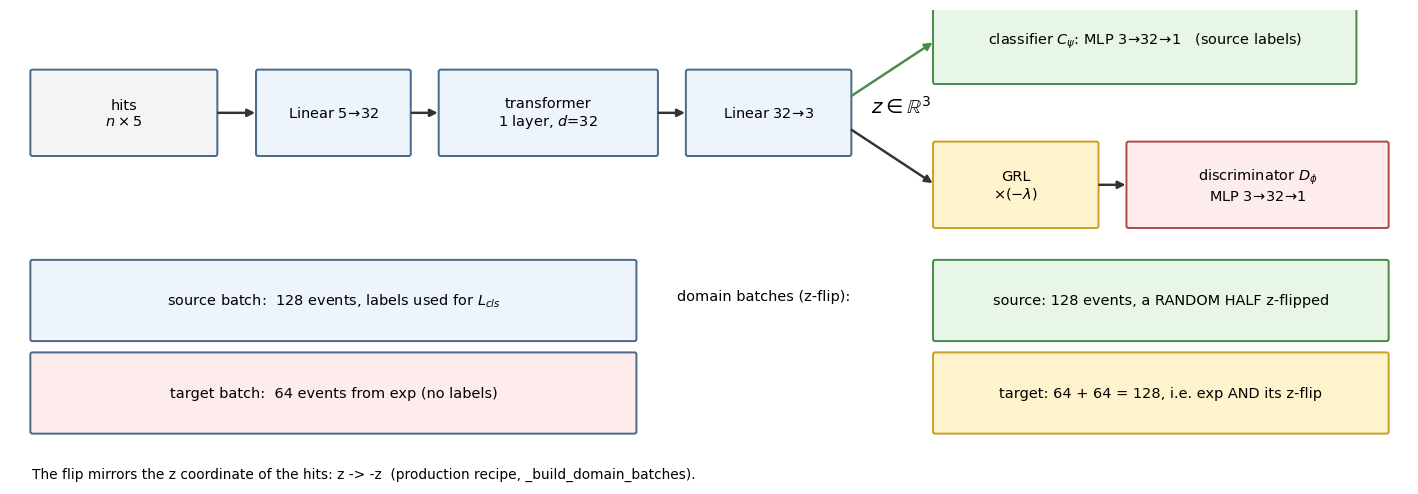

In [3]:
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.set_xlim(0, 13); ax.set_ylim(0, 4.6); ax.axis("off")


def box(x, y, w, h, text, fc="#eef4fb", ec="#4a6b8a", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)


def arrow(p, q, color="#333", ls="-"):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6, ls=ls))


box(0.2, 3.2, 1.7, 0.8, "hits\n$n\\times 5$", fc="#f4f4f4")
box(2.3, 3.2, 1.4, 0.8, "Linear $5\\!\\to\\!32$")
box(4.0, 3.2, 2.0, 0.8, "transformer\n1 layer, $d$=32")
box(6.3, 3.2, 1.5, 0.8, "Linear $32\\!\\to\\!3$")
ax.text(8.0, 3.6, "$z \\in \\mathbb{R}^3$", fontsize=13)
for a, b in [((1.9, 3.6), (2.3, 3.6)), ((3.7, 3.6), (4.0, 3.6)), ((6.0, 3.6), (6.3, 3.6))]:
    arrow(a, b)

box(8.6, 3.9, 3.9, 0.8, "classifier $C_\\psi$: MLP $3\\!\\to\\!32\\!\\to\\!1$   (source labels)",
    fc="#e8f6e8", ec="#4a8a4a")
box(8.6, 2.5, 1.5, 0.8, "GRL\n$\\times(-\\lambda)$", fc="#fff3cd", ec="#c9a227")
box(10.4, 2.5, 2.4, 0.8, "discriminator $D_\\phi$\nMLP $3\\!\\to\\!32\\!\\to\\!1$", fc="#fdeceb",
    ec="#b04a4a")
arrow((7.8, 3.75), (8.6, 4.3), "#4a8a4a")
arrow((7.8, 3.45), (8.6, 2.9))
arrow((10.1, 2.9), (10.4, 2.9))

box(0.2, 1.4, 5.6, 0.75, "source batch:  128 events, labels used for $L_{cls}$", fc="#eef4fb")
box(0.2, 0.5, 5.6, 0.75, "target batch:  64 events from exp (no labels)", fc="#fdeceb")

ax.text(6.2, 1.78, "domain batches (z-flip):", fontsize=9.5)
box(8.6, 1.4, 4.2, 0.75, "source: 128 events, a RANDOM HALF z-flipped", fc="#e8f6e8", ec="#4a8a4a")
box(8.6, 0.5, 4.2, 0.75, "target: 64 + 64 = 128, i.e. exp AND its z-flip",
    fc="#fff3cd", ec="#c9a227")
ax.text(0.2, 0.05, "The flip mirrors the z coordinate of the hits: z -> -z  "
                   "(production recipe, _build_domain_batches).", fontsize=9)
plt.tight_layout(); plt.show()

### Why the $z$-flip, and what it does to the clouds

The detector is not symmetric under $z \to -z$ (more instrumented volume above than below), so the
domains differ in their up/down composition for purely instrumental reasons. If the domain
discriminator were allowed to use orientation, the encoder could satisfy it by erasing orientation —
that is, by destroying the single most physical feature for a neutrino search (neutrinos arrive from
below). The production recipe therefore makes orientation a **non-cue for the domain**: every source
batch gets a random half of its events mirrored, and every target batch is accompanied by its own
mirror. Both domains then contain the same 50/50 mix of orientations, and "up-going" carries no
domain information — but it still carries class information, because the *class* loss sees the
source events with their true (unflipped) labels only.

The orange cloud below is that mirror image, evaluated on held-out events.

## 3. What is measured

| meter | procedure | question |
|---|---|---|
| `acc_src` | class accuracy on held-out source | is the class task learned? |
| `auc_disc` | live discriminator, source vs target | is the current reader confused? |
| `probe_lin`, `probe_mlp` | fresh logistic regression / MLP on frozen $z$ | can a *fresh* reader still tell the domains apart? |
| `score` of each cloud | the classifier's output for the four clouds | what does the classifier say about real data? |
| `excess` | fraction of `exp` above a threshold set at 1% on the source background | the false-positive excess |
| `\\|Δ_cls\\|`, `\\|Δ_dom\\|`, `\\|Δ_flip\\|` | lengths of the mean differences in $z$-space | the geometry of the four clouds |

All probes see **standardized** $z$ (the scale of the representation is arbitrary). The `exp` cloud
has no labels — never, in any version of this analysis — so everything about it is a distribution,
not an accuracy.

In [4]:
class Rev(torch.autograd.Function):
    # gradient reversal: identity forward, gradient multiplied by -lam backward
    @staticmethod
    def forward(ctx, z, lam):
        ctx.lam = lam
        return z

    @staticmethod
    def backward(ctx, grad):
        return -ctx.lam * grad, None


def collate(events, flip=False):
    # pad a list of (n_hits, 5) events into (B, L, 5) + boolean mask; optionally z-flip
    L = max(len(e) for e in events)
    X = np.zeros((len(events), L, 5), dtype=np.float32)
    M = np.zeros((len(events), L), dtype=bool)
    for i, e in enumerate(events):
        X[i, :len(e)] = e
        M[i, :len(e)] = True
    X, M = torch.tensor(X), torch.tensor(M)
    if flip:
        X[:, :, Z_INDEX] = torch.where(M, -X[:, :, Z_INDEX], X[:, :, Z_INDEX])
    return X, M


class TinyEncoder(nn.Module):
    # miniature of the production encoder: project -> CLS + transformer layer -> z
    def __init__(self, d_model=32, nhead=2, z_dim=3):
        super().__init__()
        self.proj = nn.Linear(5, d_model)
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos = nn.Parameter(0.02 * torch.randn(1, MAX_HITS + 1, d_model))
        layer = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=64, dropout=0.0,
                                           batch_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=1)
        self.out = nn.Linear(d_model, z_dim)

    def forward(self, x, mask):
        h = self.proj(x)
        h = torch.cat([self.cls.expand(x.shape[0], -1, -1), h], dim=1) + self.pos[:, :x.shape[1] + 1]
        m = torch.cat([torch.ones(x.shape[0], 1, dtype=torch.bool), mask], dim=1)
        h = self.transformer(h, src_key_padding_mask=~m)
        return self.out(h[:, 0])


def standardize(z):
    mu, sd = z.mean(0), z.std(0) + 1e-6
    return (z - mu) / sd


def probe_auc(za, zb, kind="linear", steps=400, seed=0):
    # fresh reader separating two frozen clouds
    za, zb = standardize(za), standardize(zb)
    X = np.vstack([za.numpy(), zb.numpy()])
    y = np.r_[np.zeros(len(za)), np.ones(len(zb))]
    if kind == "linear":
        clf = LogisticRegression(max_iter=2000).fit(X, y)
        return roc_auc_score(y, clf.predict_proba(X)[:, 1])
    torch.manual_seed(seed)
    Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.float32)
    net = nn.Sequential(nn.Linear(X.shape[1], 32), nn.ReLU(), nn.Linear(32, 1))
    opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    with torch.enable_grad():
        for _ in range(steps):
            opt.zero_grad()
            nn.functional.binary_cross_entropy_with_logits(net(Xt).squeeze(), yt).backward()
            opt.step()
    with torch.no_grad():
        return roc_auc_score(y, torch.sigmoid(net(Xt).squeeze()).numpy())


print("meters ready")

meters ready


## 4. Training

Batch construction follows the production script: the classifier sees 128 source events with their
labels; the domain branch sees 128 source events (a random half $z$-flipped) against 128 target
events (`exp` **and** its mirror). The held-out 4000 events per domain are never trained on — they
are the clouds we watch.

In [ ]:
hold_mu = [src_events[k] for k in np.arange(N_TRAIN, N_SAMPLE) if src_type[k] == 0]
hold_nu = [src_events[k] for k in np.arange(N_TRAIN, N_SAMPLE) if src_type[k] > 0]
hold_ex = tgt_events[4000:]
print(f"held out: {len(hold_mu)} muatm, {len(hold_nu)} neutrinos, {len(hold_ex)} exp")


def train(steps=1500, lr=1e-3, n_src=128, n_tgt=64, log_every=150, seed=0, lam_max=1.0,
          gamma=10.0):
    torch.manual_seed(seed)
    enc = TinyEncoder()
    head = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 1))
    dis = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 1))
    opt = torch.optim.Adam(list(enc.parameters()) + list(head.parameters())
                           + list(dis.parameters()), lr=lr)
    bce = nn.functional.binary_cross_entropy_with_logits
    log = []

    mu_idx = np.arange(N_TRAIN)[src_type[:N_TRAIN] == 0]
    nu_idx = np.arange(N_TRAIN)[src_type[:N_TRAIN] > 0]

    for step in range(steps + 1):
        # ---- classification batch: source, labelled, no flip ----
        b_mu = np.random.choice(mu_idx, n_src // 2)
        b_nu = np.random.choice(nu_idx, n_src // 2)
        x_cls, m_cls = collate([src_events[k] for k in b_mu] + [src_events[k] for k in b_nu])
        y_cls = torch.cat([torch.zeros(n_src // 2), torch.ones(n_src // 2)])

        # ---- domain batches: as in the production script ----
        src_pool = [src_events[k] for k in np.random.choice(np.arange(N_TRAIN), n_src)]
        tgt_pool = [tgt_events[k] for k in np.random.choice(np.arange(4000), n_tgt)]
        x_sd, m_sd = collate(src_pool)
        flip_src = torch.randperm(n_src)[:n_src // 2]           # a random half of the source
        x_sd[flip_src, :, Z_INDEX] = torch.where(m_sd[flip_src],
                                                 -x_sd[flip_src, :, Z_INDEX],
                                                 x_sd[flip_src, :, Z_INDEX])
        x_td = torch.cat([collate(tgt_pool)[0], collate(tgt_pool, flip=True)[0]])   # exp + mirror
        m_td = torch.cat([collate(tgt_pool)[1], collate(tgt_pool, flip=True)[1]])

        lam = lam_max * (2.0 / (1.0 + np.exp(-gamma * step / steps)) - 1.0)

        z_cls = enc(x_cls, m_cls)
        z_sd, z_td = enc(x_sd, m_sd), enc(x_td, m_td)
        cls = bce(head(z_cls).squeeze(), y_cls)
        dom = 0.5 * (bce(dis(Rev.apply(z_sd, lam)).squeeze(), torch.zeros(len(z_sd)))
                     + bce(dis(Rev.apply(z_td, lam)).squeeze(), torch.ones(len(z_td))))
        opt.zero_grad()
        (cls + dom).backward()
        opt.step()

        if step % log_every == 0:
            enc.eval()
            with torch.no_grad():
                C = {}
                C["b"] = enc(*collate(hold_mu))
                C["g"] = enc(*collate(hold_nu))
                C["r"] = enc(*collate(hold_ex))
                C["o"] = enc(*collate(hold_ex, flip=True))
                acc = float(((head(torch.cat([C["b"], C["g"]])).squeeze() > 0).float()
                             == torch.cat([torch.zeros(len(C["b"])), torch.ones(len(C["g"]))])
                             ).float().mean())
                auc_disc = roc_auc_score(
                    np.r_[np.zeros(len(C["b"]) + len(C["g"])), np.ones(len(C["r"]))],
                    np.r_[dis(torch.cat([C["b"], C["g"]])).squeeze().numpy(),
                          dis(C["r"]).squeeze().numpy()])
                score = {k: head(C[k]).squeeze().numpy() for k in "bgro"}
                thr = float(np.quantile(score["b"], 0.99))
                excess = float((score["r"] > thr).mean())
                excess_flip = float((score["o"] > thr).mean())
                d_cls = C["g"].mean(0) - C["b"].mean(0)
                d_dom = C["r"].mean(0) - C["b"].mean(0)
                d_flip = C["o"].mean(0) - C["r"].mean(0)
                clouds = {k: C[k].numpy().copy() for k in "bgro"}
            pl = probe_auc(torch.cat([C["b"], C["g"]]), C["r"], "linear")
            pm = probe_auc(torch.cat([C["b"], C["g"]]), C["r"], "mlp")
            enc.train()
            log.append(dict(step=step, lam=lam, cls=float(cls), dom=float(dom), acc=acc,
                            auc_disc=auc_disc, probe_lin=pl, probe_mlp=pm,
                            l_cls=float(d_cls.norm()), l_dom=float(d_dom.norm()),
                            l_flip=float(d_flip.norm()), excess=excess, excess_flip=excess_flip,
                            clouds=clouds, score=score))
    return enc, head, dis, log


t0 = time.time()
enc, head, dis, log = train()
print(f"trained in {time.time()-t0:.0f} s")
print(f"{'step':>5}{'lam':>6}{'cls':>8}{'dom':>7}{'acc_src':>9}{'auc_disc':>10}"
      f"{'probe_lin':>10}{'probe_mlp':>10}{'|Δcls|':>8}{'|Δdom|':>8}{'|Δflip|':>8}{'excess':>8}")
for r in log:
    print(f"{r['step']:>5}{r['lam']:>6.2f}{r['cls']:>8.4f}{r['dom']:>7.3f}{r['acc']:>9.3f}"
          f"{r['auc_disc']:>10.3f}{r['probe_lin']:>10.3f}{r['probe_mlp']:>10.3f}"
          f"{r['l_cls']:>8.2f}{r['l_dom']:>8.2f}{r['l_flip']:>8.2f}{r['excess']:>8.3f}")

held out: 1961 muatm, 2039 neutrinos, 16000 exp


/home/albert/miniconda3/envs/baikal25/lib/python3.10/site-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


## 5. Analytics

### 5.1 Training curves

In [ ]:
steps = [r["step"] for r in log]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.7))
axes[0].plot(steps, [r["cls"] for r in log], "-o", ms=3, color="#2ca02c", label="class loss")
axes[0].plot(steps, [r["dom"] for r in log], "-s", ms=3, color="#d62728", label="domain loss")
axes[0].axhline(np.log(2), ls="--", color="gray", label="$\\ln 2$")
axes[0].set_xlabel("step"); axes[0].legend(fontsize=8.5); axes[0].set_title("losses")

axes[1].plot(steps, [r["acc"] for r in log], "-o", ms=3, color="#2ca02c")
axes[1].set_xlabel("step"); axes[1].set_ylabel("class accuracy (source)")
axes[1].set_ylim(0.4, 1.02); axes[1].set_title("the class task")

axes[2].plot(steps, [r["auc_disc"] for r in log], "-o", ms=3, color="#d62728",
             label="live discriminator")
axes[2].plot(steps, [r["probe_lin"] for r in log], "-s", ms=3, color="#1f77b4",
             label="fresh linear probe")
axes[2].plot(steps, [r["probe_mlp"] for r in log], "-^", ms=3, color="#2ca02c",
             label="fresh nonlinear probe")
axes[2].axhline(0.5, ls=":", color="gray"); axes[2].set_ylim(0.2, 1.02)
axes[2].set_xlabel("step"); axes[2].legend(fontsize=8); axes[2].set_title("who reads the domain")
plt.tight_layout(); plt.show()

### 5.2 The geometry of the four clouds

The class difference is the yardstick: everything is measured in units of it.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(steps, [r["l_cls"] for r in log], "-o", ms=3, color="#2ca02c", label="$\\|\\Delta_{cls}\\|$")
axes[0].plot(steps, [r["l_dom"] for r in log], "-s", ms=3, color="#d62728",
             label="$\\|\\Delta_{dom}\\|$ (exp vs mc)")
axes[0].plot(steps, [r["l_flip"] for r in log], "-^", ms=3, color="#ff7f0e",
             label="$\\|\\Delta_{flip}\\|$ (exp vs its mirror)")
axes[0].set_xlabel("step"); axes[0].set_ylabel("length in $z$-space"); axes[0].legend(fontsize=8)
axes[0].set_title("the three differences")

axes[1].plot(steps, [r["excess"] for r in log], "-s", ms=3, color="#d62728", label="exp")
axes[1].plot(steps, [r["excess_flip"] for r in log], "-^", ms=3, color="#ff7f0e",
             label="exp, z-flipped")
axes[1].axhline(0.01, ls=":", color="gray", label="1% (by construction)")
axes[1].set_xlabel("step"); axes[1].set_ylabel("fraction above the threshold")
axes[1].legend(fontsize=8)
axes[1].set_title("what the classifier says:\\nthe 'excess' above a 1%-background threshold")
plt.tight_layout(); plt.show()

### 5.3 The comic: the four clouds in $z$-space

One panel per checkpoint, each standardized on its own to keep the geometry visible (the raw scale
of $z$ is arbitrary and drifts). Arrows: green = class difference (muatm → neutrinos), red = domain
difference (muatm → exp), orange = the mirror (exp → its $z$-flip).

In [ ]:
picks = np.unique(np.linspace(0, len(log) - 1, 9).round().astype(int))
fig = plt.figure(figsize=(15.5, 14))
for j, pick in enumerate(picks):
    r = log[pick]
    ax = fig.add_subplot(3, 3, j + 1, projection="3d")
    allz = np.vstack([r["clouds"][k] for k in "bgro"])
    mu, sd = allz.mean(0), allz.std(0) + 1e-9
    C = {k: (r["clouds"][k] - mu) / sd for k in "bgro"}
    for k in "bgro":
        ax.scatter(C[k][::2, 0], C[k][::2, 1], C[k][::2, 2], s=2, alpha=0.3, color=COLORS[k],
                   label=NAMES[k])
    cb, cg, cr, co = (C[k].mean(0) for k in "bgro")
    ax.quiver(*cb, *(cg - cb), color="#2ca02c", lw=2.4, arrow_length_ratio=0.2)
    ax.quiver(*cb, *(cr - cb), color="#d62728", lw=2.4, arrow_length_ratio=0.2)
    ax.quiver(*cr, *(co - cr), color="#ff7f0e", lw=2.4, arrow_length_ratio=0.2)
    lim = 2.4
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_title(f"step {r['step']}   $\\lambda$={r['lam']:.2f}\n"
                 f"acc {r['acc']:.2f} · probe lin {r['probe_lin']:.2f} · "
                 f"excess {r['excess']:.2f}", fontsize=9)
    if j == 0:
        ax.legend(fontsize=6.5, loc="upper right")
fig.suptitle("the real data in a 3D representation: four clouds over training", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

### 5.4 The classifier's verdict on the four clouds

Histograms of the classifier's output. The threshold is placed at 1% of the source background — the
same convention as in the production analysis, where everything above it counts as "neutrino-like".

In [ ]:
last = log[-1]
fig, ax = plt.subplots(figsize=(10, 3.9))
bins = np.linspace(min(last["score"]["b"].min(), last["score"]["r"].min()),
                   max(last["score"]["g"].max(), last["score"]["o"].max()), 70)
for k in "bgro":
    ax.hist(last["score"][k], bins=bins, alpha=0.55, color=COLORS[k], label=NAMES[k])
thr = float(np.quantile(last["score"]["b"], 0.99))
ax.axvline(thr, ls="--", color="black")
ax.text(thr, ax.get_ylim()[1] * 0.9, "  1% of the source background", fontsize=9)
ax.set_xlabel("class logit"); ax.set_yticks([]); ax.legend(fontsize=8)
ax.set_title("the classifier on the four clouds (final model)", fontsize=10)
plt.tight_layout(); plt.show()

print(f"above the threshold: exp {last['excess']:.1%}, exp z-flipped {last['excess_flip']:.1%}"
      f"   (source background: 1.0%)")

### 5.5 Robustness across seeds

In [ ]:
rows = []
for sd in (0, 1, 2):
    _, _, _, lg = train(steps=800, log_every=800, seed=sd)
    f = lg[-1]
    rows.append((sd, f["acc"], f["auc_disc"], f["probe_lin"], f["probe_mlp"], f["l_cls"],
                 f["l_dom"], f["l_flip"], f["excess"]))
print(f"{'seed':>5}{'acc_src':>9}{'auc_disc':>10}{'probe_lin':>10}{'probe_mlp':>10}"
      f"{'|Δcls|':>8}{'|Δdom|':>8}{'|Δflip|':>8}{'excess':>8}")
for r in rows:
    print(f"{r[0]:>5}{r[1]:>9.3f}{r[2]:>10.3f}{r[3]:>10.3f}{r[4]:>10.3f}"
          f"{r[5]:>8.2f}{r[6]:>8.2f}{r[7]:>8.2f}{r[8]:>8.3f}")

## 6. What this shows, and what it does not

**What it shows.**

1. A three-dimensional representation of the *real* hit data is enough for the class task: the
   classifier separates muatm from neutrinos on held-out events at high accuracy, and it does so
   from sequences of a handful of hits.
2. The $z$-flip does exactly what the recipe intends: the mirror of `exp` is mapped far away from
   `exp` itself — as far as the class separation — which means orientation is a *strong* feature of
   the representation, while the domain loss cannot exploit it (both domains contain the same
   50/50 orientation mix).
3. `exp` (red) sits close to the muon cloud in this representation, while the mirrored `exp`
   (orange) lands on the neutrino side. The excess measured on the mirrored cloud is therefore the
   "fake up-going background" rate — the population a neutrino search has to reject — and it is
   much larger than the excess of the unmirrored data.

**What it does not show.** This is a 20 000-event sample, 64 hits deep, with a three-dimensional
bottleneck and a single transformer layer. None of the numbers here transfer to the production
model; what transfers is the *picture*: what the geometry of the four clouds looks like, and which
meters are worth watching (a fresh probe, the cloud geometry, and the score distributions of the
four clouds separately).

### Exercises

1. Increase $z$ to 8 and re-run. Does the excess of the mirrored cloud grow or shrink, and what
   happens to the probe AUC?
2. Remove the $z$-flip from the domain batches and see what the discriminator does with orientation
   — that is precisely the failure mode the recipe is designed to prevent.
3. Replace the 1%-background threshold with the threshold that keeps the *mirrored* exp cloud at
   1%. What does the classifier's signal efficiency do?